# Pembagian Train/Test dan Estimasi SARIMA

Langkah 4 (pembagian data) dan estimasi ketujuh kandidat SARIMA dari langkah 3.

Aturan yang dipakai:
- Split **kronologis** (tanpa shuffle): 80% awal = train, 20% akhir = test.
- Semua estimasi parameter dan pemilihan model hanya memakai **data train**. Data test hanya dipakai sekali di akhir untuk evaluasi.
- Evaluasi test memakai **prediksi satu langkah ke depan (one-step-ahead)** dengan parameter tetap dari train. Skema yang sama dipakai untuk LSTM di notebook 05 supaya perbandingannya adil.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

import common as cm

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})
S = cm.S

## 1. Pembagian train/test

In [2]:
y = cm.muat_data()
train, test = cm.split_kronologis(y)

pd.DataFrame({
    "Bagian": ["Train", "Test"],
    "Mulai": [train.index[0].date(), test.index[0].date()],
    "Akhir": [train.index[-1].date(), test.index[-1].date()],
    "n": [len(train), len(test)],
    "Proporsi": [f"{len(train)/len(y):.0%}", f"{len(test)/len(y):.0%}"],
    "Rata-rata jk": [train.mean().round(1), test.mean().round(1)],
}).set_index("Bagian")

,Mulai,Akhir,n,Proporsi,Rata-rata jk
Bagian,,,,,
Train,2023-01-01,2026-01-10,1106,80%,793.3
Test,2026-01-11,2026-10-13,276,20%,866.9


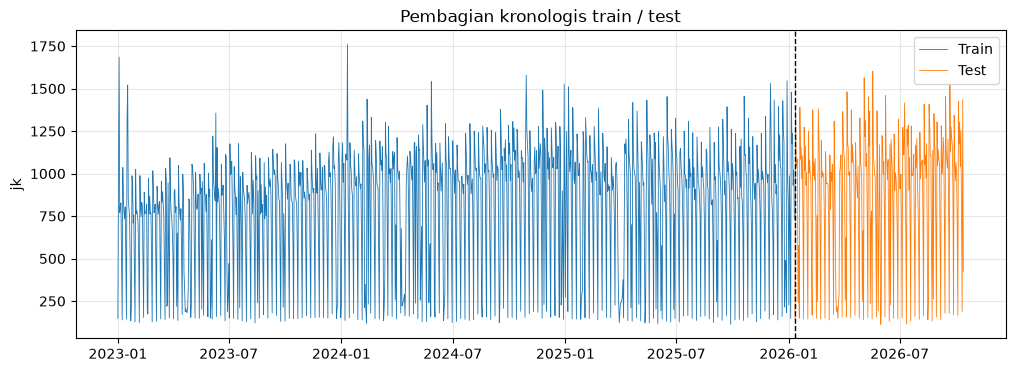

In [3]:
fig, ax = plt.subplots()
ax.plot(train, lw=.6, label="Train")
ax.plot(test, lw=.6, color="tab:orange", label="Test")
ax.axvline(test.index[0], color="k", ls="--", lw=1)
ax.set(title="Pembagian kronologis train / test", ylabel="jk")
ax.legend()
plt.show()

Test mencakup 276 hari (± 39 minggu), sehingga setiap hari dalam seminggu muncul puluhan kali. Rata-rata jk test (≈867) sedikit lebih tinggi daripada train (≈793), jadi ada sedikit pergeseran level naik. Ini berlaku sama untuk kedua model.

## 2. Estimasi kandidat pada data train

Untuk tiap kandidat dihitung: AIC, BIC, signifikansi parameter (semua p < 0,05?), **invertibilitas** (semua akar polinomial MA di luar lingkaran satuan), dan uji Ljung-Box pada residual (lag 14 dan 28). Estimasi sengaja dijalankan tanpa memaksa invertibilitas (`enforce_invertibility=False`) supaya pelanggarannya terlihat, bukan disembunyikan. Residual `S + d` observasi pertama dibuang karena dipengaruhi inisialisasi differencing.

Model dengan d = 0 dan D = 1 tidak diberi konstanta (`trend="n"`), karena selisih musiman sudah menghilangkan level.

In [4]:
kandidat = {
    "M1": ((0, 0, 1), (0, 1, 1)),
    "M2": ((1, 0, 0), (0, 1, 1)),
    "M3": ((1, 0, 1), (0, 1, 1)),
    "M4": ((0, 1, 1), (0, 1, 1)),
    "M5": ((0, 1, 2), (0, 1, 1)),
    "M6": ((1, 1, 1), (0, 1, 1)),
    "M7": ((1, 0, 1), (1, 1, 1)),
}

def fit(order, sorder, data=train):
    return SARIMAX(data, order=order, seasonal_order=sorder + (S,), trend="n",
                   enforce_stationarity=False, enforce_invertibility=False
                   ).fit(disp=False, maxiter=200)

hasil_fit, baris = {}, []
for kode, (order, sorder) in kandidat.items():
    res = fit(order, sorder)
    hasil_fit[kode] = res
    skip = S + order[1]
    resid = res.resid.iloc[skip:]
    k = order[0] + order[2] + sorder[0] + sorder[2]
    lb = acorr_ljungbox(resid, lags=[14, 28], model_df=k)
    pv = res.pvalues.drop("sigma2")
    baris.append({
        "Kode": kode, "Model": f"SARIMA{order}{sorder}[{S}]",
        "AIC": res.aic, "BIC": res.bic,
        "Param signifikan": bool((pv < .05).all()),
        "LB p (lag 14)": lb["lb_pvalue"].iloc[0],
        "LB p (lag 28)": lb["lb_pvalue"].iloc[1],
        "Invertibel": bool(len(res.maroots) == 0 or np.abs(res.maroots).min() > 1),
        "Konvergen": bool(res.mle_retvals.get("converged", True)),
    })
tabel = pd.DataFrame(baris).set_index("Kode")
tabel.round(4)

,Model,AIC,BIC,Param signifikan,LB p (lag 14),LB p (lag 28),Invertibel,Konvergen
Kode,,,,,,,,
M1,"SARIMA(0, 0, 1)(0, 1, 1)[7]",14645.8871,14660.8689,True,0.1981,0.4487,False,True
M2,"SARIMA(1, 0, 0)(0, 1, 1)[7]",14656.4034,14671.3879,True,0.3213,0.5875,True,True
M3,"SARIMA(1, 0, 1)(0, 1, 1)[7]",14644.2823,14664.2580,False,0.3150,0.5832,False,True
M4,"SARIMA(0, 1, 1)(0, 1, 1)[7]",14725.3426,14740.3217,True,0.0000,0.0000,False,True
M5,"SARIMA(0, 1, 2)(0, 1, 1)[7]",14627.3622,14647.3306,True,0.1077,0.3465,False,True
M6,"SARIMA(1, 1, 1)(0, 1, 1)[7]",14637.6554,14657.6275,True,0.2213,0.4888,False,True
M7,"SARIMA(1, 0, 1)(1, 1, 1)[7]",14645.3444,14670.3140,False,0.2580,0.5552,True,True


In [5]:
tabel["Residual white noise"] = (tabel[["LB p (lag 14)", "LB p (lag 28)"]] >= .05).all(axis=1)
tabel.sort_values("AIC").round(4)

,Model,AIC,BIC,Param signifikan,LB p (lag 14),LB p (lag 28),Invertibel,Konvergen,Residual white noise
Kode,,,,,,,,,
M5,"SARIMA(0, 1, 2)(0, 1, 1)[7]",14627.3622,14647.3306,True,0.1077,0.3465,False,True,True
M6,"SARIMA(1, 1, 1)(0, 1, 1)[7]",14637.6554,14657.6275,True,0.2213,0.4888,False,True,True
M3,"SARIMA(1, 0, 1)(0, 1, 1)[7]",14644.2823,14664.2580,False,0.3150,0.5832,False,True,True
M7,"SARIMA(1, 0, 1)(1, 1, 1)[7]",14645.3444,14670.3140,False,0.2580,0.5552,True,True,True
M1,"SARIMA(0, 0, 1)(0, 1, 1)[7]",14645.8871,14660.8689,True,0.1981,0.4487,False,True,True
M2,"SARIMA(1, 0, 0)(0, 1, 1)[7]",14656.4034,14671.3879,True,0.3213,0.5875,True,True,True
M4,"SARIMA(0, 1, 1)(0, 1, 1)[7]",14725.3426,14740.3217,True,0.0000,0.0000,False,True,False


In [6]:
for kode in kandidat:
    print(kode, "\n", hasil_fit[kode].summary().tables[1], "\n")

M1 
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.2944      0.019     15.155      0.000       0.256       0.332
ma.S.L7       -1.0823      0.013    -84.140      0.000      -1.107      -1.057
sigma2      3.377e+04    925.902     36.470      0.000     3.2e+04    3.56e+04

M2 
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2979      0.018     16.937      0.000       0.263       0.332
ma.S.L7       -0.9251      0.011    -85.237      0.000      -0.946      -0.904
sigma2      3.944e+04    840.047     46.947      0.000    3.78e+04    4.11e+04

M3 
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2210      0.074      

## 3. Pemilihan model

Kriteria (hanya dari data train): konvergen, parameter signifikan, invertibel, residual lolos Ljung-Box, lalu AIC terkecil. Jika tidak ada kandidat yang lolos semuanya, dipakai AIC terkecil dan keterbatasannya dicatat.

**Catatan:** koefisien MA musiman pada M1, M3, M5, M6 berada sedikit di bawah −1 (≈ −1,06 sampai −1,08), artinya model non-invertibel; ini tanda differencing musiman D = 1 sedikit berlebih untuk pola mingguan yang sangat stabil. Model non-invertibel tidak valid untuk inferensi (interval, uji parameter), sehingga dikeluarkan dari pemilihan meskipun AIC-nya lebih kecil. Perbedaan AIC antar model yang lolos kecil, jadi pilihan ini tidak mengubah kesimpulan secara berarti (lihat tabel test di bawah).

In [7]:
lolos = tabel[tabel["Param signifikan"] & tabel["Invertibel"] & tabel["Residual white noise"] & tabel["Konvergen"]]
if len(lolos):
    terbaik = lolos["AIC"].idxmin()
    print("Dipilih dari kandidat yang lolos semua kriteria:", list(lolos.index))
else:
    terbaik = tabel["AIC"].idxmin()
    print("Tidak ada kandidat lolos semua kriteria; dipilih AIC terkecil.")
print("Model terpilih:", terbaik, tabel.loc[terbaik, "Model"])

Dipilih dari kandidat yang lolos semua kriteria: ['M2']
Model terpilih: M2 SARIMA(1, 0, 0)(0, 1, 1)[7]


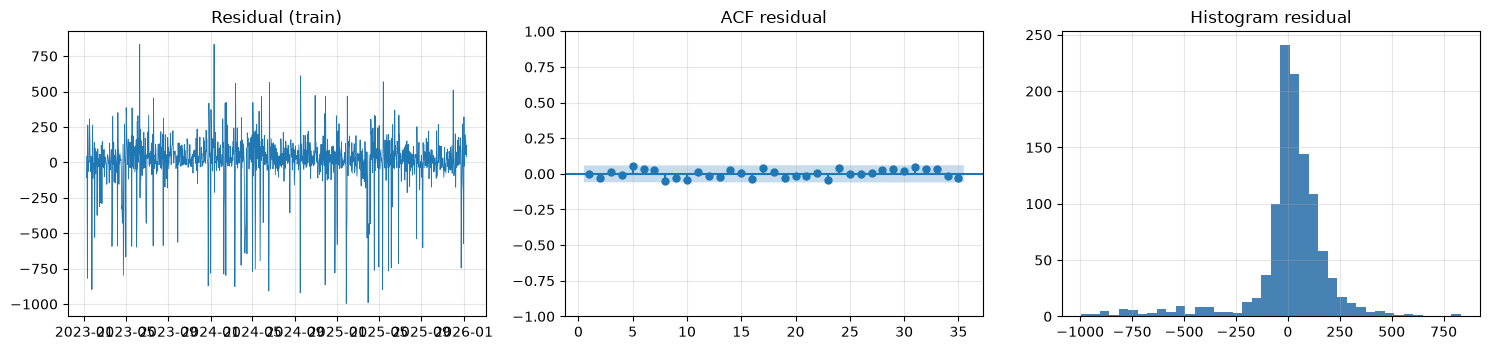

In [8]:
res_b = hasil_fit[terbaik]
order_b, sorder_b = kandidat[terbaik]
skip = S + order_b[1]
resid = res_b.resid.iloc[skip:]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(resid, lw=.6); axes[0].set_title("Residual (train)")
plot_acf(resid, lags=35, zero=False, ax=axes[1], title="ACF residual")
axes[2].hist(resid, bins=40, color="steelblue"); axes[2].set_title("Histogram residual")
plt.tight_layout(); plt.show()

## 4. Evaluasi pada data test (one-step-ahead)

Parameter dari train dipertahankan; model hanya "melihat" nilai aktual hingga hari sebelumnya untuk memprediksi hari berikutnya. Tabel di bawah menampilkan semua kandidat **hanya sebagai informasi**. Pemilihan sudah dilakukan di atas dan tidak diubah berdasarkan hasil test.

In [9]:
def prediksi_satu_langkah(res):
    penuh = res.apply(y, refit=False)  # parameter tetap, data sampai akhir test
    return penuh.get_prediction(start=test.index[0]).predicted_mean

pred_test = {k: prediksi_satu_langkah(r) for k, r in hasil_fit.items()}

eval_test = pd.DataFrame({k: cm.metrik(test, p) for k, p in pred_test.items()}).T
eval_test.insert(0, "Model", tabel["Model"])
eval_test.round(2)

,Model,RMSE,MAE,MAPE (%)
M1,"SARIMA(0, 0, 1)(0, 1, 1)[7]",226.25,133.13,27.72
M2,"SARIMA(1, 0, 0)(0, 1, 1)[7]",226.19,133.35,27.76
M3,"SARIMA(1, 0, 1)(0, 1, 1)[7]",226.20,133.13,27.66
M4,"SARIMA(0, 1, 1)(0, 1, 1)[7]",228.69,140.03,29.98
M5,"SARIMA(0, 1, 2)(0, 1, 1)[7]",225.25,131.49,27.56
M6,"SARIMA(1, 1, 1)(0, 1, 1)[7]",225.47,131.92,27.84
M7,"SARIMA(1, 0, 1)(1, 1, 1)[7]",226.75,133.23,27.71


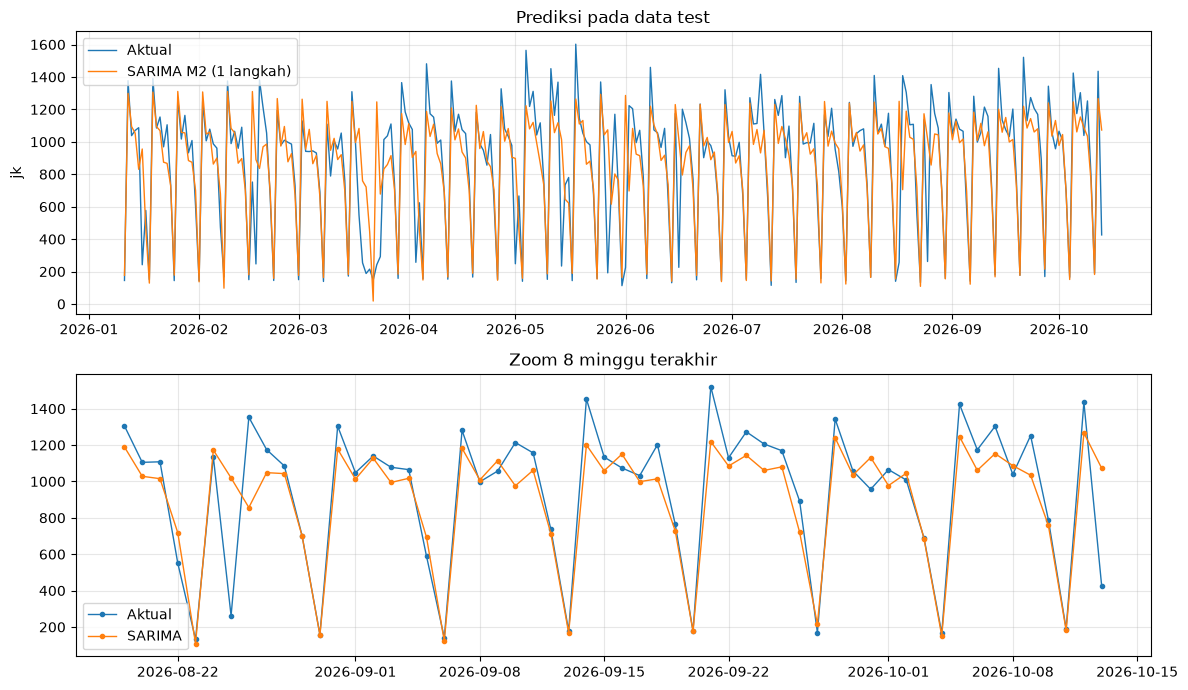

,SARIMA M2
RMSE,226.19
MAE,133.35
MAPE (%),27.76


In [10]:
p = pred_test[terbaik]
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(test, lw=1, label="Aktual")
axes[0].plot(p, lw=1, label=f"SARIMA {terbaik} (1 langkah)")
axes[0].set(title="Prediksi pada data test", ylabel="jk"); axes[0].legend()
axes[1].plot(test.index[-56:], test.iloc[-56:], marker="o", ms=3, lw=1, label="Aktual")
axes[1].plot(p.iloc[-56:], marker="o", ms=3, lw=1, label="SARIMA")
axes[1].set(title="Zoom 8 minggu terakhir"); axes[1].legend()
plt.tight_layout(); plt.show()

pd.Series(cm.metrik(test, p), name=f"SARIMA {terbaik}").round(2).to_frame()

### Pembanding: baseline seasonal naive

Prediksi `y_t = y_{t-7}`. Model yang lebih rumit hanya berguna jika mengalahkan baseline sederhana ini.

In [11]:
naive = y.shift(S).loc[test.index]
pd.DataFrame({"Seasonal naive": cm.metrik(test, naive),
              f"SARIMA {terbaik}": cm.metrik(test, p)}).T.round(2)

,RMSE,MAE,MAPE (%)
Seasonal naive,325.20,191.65,35.88
SARIMA M2,226.19,133.35,27.76


In [12]:
cm.HASIL_DIR.mkdir(parents=True, exist_ok=True)
pd.DataFrame({"aktual": test, "sarima": p, "naive": naive}).to_csv(cm.HASIL_DIR / "pred_sarima.csv")
tabel.to_csv(cm.HASIL_DIR / "sarima_kandidat.csv")
print("Disimpan di", cm.HASIL_DIR)

Disimpan di D:\Kuliah\Semester 5\ADW\sarima\data\hasil
